## **Import Library** ##

In [ ]:
!pip install darts

In [ ]:
# ==================================================
# IMPORT LIBRARY (FINAL)
# ==================================================
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Darts core
from darts import TimeSeries
from darts.models import (
    RegressionModel,
    LightGBMModel,
    NHiTSModel
)
from darts.dataprocessing.transformers import Scaler
from darts.metrics import rmse, smape

# sklearn model
from sklearn.ensemble import RandomForestRegressor

# reproducibility
import random
SEED = 42
np.random.seed(SEED)
random.seed(SEED)


In [ ]:
# impor data
df = pd.read_excel("data fp sml.xlsx")

# Hapus kolom No kalau adaa
if "No" in df.columns:
    df = df.drop(columns=["No"])

df

,Bulan,Data
0,Jan_2010,178358
1,Feb_2010,191362
2,Mar_2010,191125
3,Apr_2010,184230
4,Mei_2010,199401
...,...,...
175,Agt_2024,613540
176,Sep_2024,591848
177,Okt_2024,554892
178,Nov_2024,472714


In [ ]:
# ============================================
# KONVERSI BULAN INDONESIA → DATETIME (FIX)
# ============================================
bulan_map = {
    "Jan": "Jan", "Feb": "Feb", "Mar": "Mar", "Apr": "Apr",
    "Mei": "May", "Jun": "Jun", "Jul": "Jul", "Agt": "Aug",
    "Sep": "Sep", "Okt": "Oct", "Nov": "Nov", "Des": "Dec"
}

# ganti prefix bulan Indonesia → Inggris
for indo, eng in bulan_map.items():
    df['Bulan'] = df['Bulan'].str.replace(indo, eng, regex=False)

# convert ke datetime (format: Jan_2020)
df['Bulan'] = pd.to_datetime(df['Bulan'], format="%b_%Y")

# jadikan index time series
df.set_index('Bulan', inplace=True)

data = df['Data'].values


Tahap awal preprocessing dilakukan dengan memastikan bahwa variabel waktu berada dalam format yang sesuai untuk analisis time series. Data awal memiliki format bulan dalam Bahasa Indonesia (misalnya Mei, Agt, Okt), sehingga dilakukan pemetaan nama bulan dari Bahasa Indonesia ke Bahasa Inggris agar dapat dikenali oleh fungsi datetime pada Python.

Setelah proses pemetaan, kolom waktu dikonversi menjadi tipe datetime dengan format bulan–tahun, kemudian dijadikan sebagai indeks data. Langkah ini bertujuan agar data memiliki struktur kronologis yang jelas dan dapat diproses sebagai deret waktu.

## **EDA**

**Plot Time Series Keseluruhan**

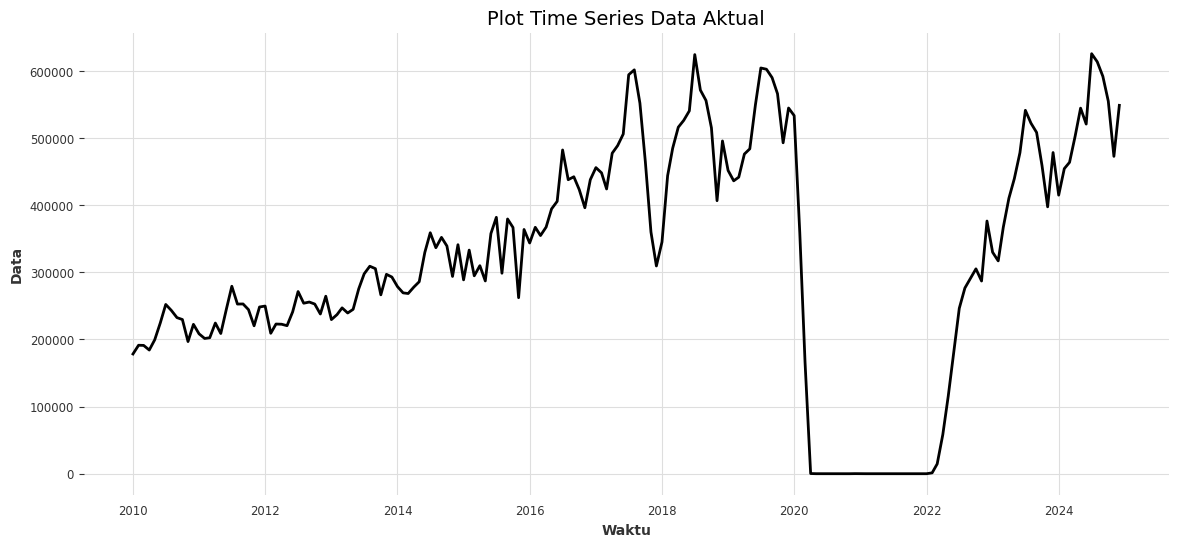

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(df.index, df['Data'], linewidth=2)
plt.title("Plot Time Series Data Aktual", fontsize=14)
plt.xlabel("Waktu")
plt.ylabel("Data")
plt.grid(True)
plt.show()

Berdasarkan plot time series periode 2010-2024, data menunjukkan **tren meningkat dalam jangka panjang** dengan fluktuasi yang semakin besar seiring waktu. Selain tren, terlihat adanya **pola musiman bulanan**, di mana nilai data berulang naik dan turun pada periode tertentu setiap tahunnya. Pada rentang waktu **2020 hingga pertengahan 2022** terjadi **penurunan ekstrem hingga mendekati nol**, yang mengindikasikan adanya **perubahan struktural akibat kejadian eksternal**. Pola ini tidak sejalan dengan tren historis sebelumnya sehingga tidak dapat dijelaskan oleh dinamika normal data. Setelah periode tersebut, data menunjukkan **fase pemulihan yang kuat**, dengan nilai yang kembali meningkat secara signifikan. Pada periode 2023-2024, level data bahkan mendekati atau melampaui kondisi sebelum penurunan ekstrem. Karakteristik ini menunjukkan bahwa data memiliki **tren, musiman, serta shock eksternal**, sehingga memerlukan pendekatan pemodelan yang mampu menangkap dinamika kompleks tersebut.


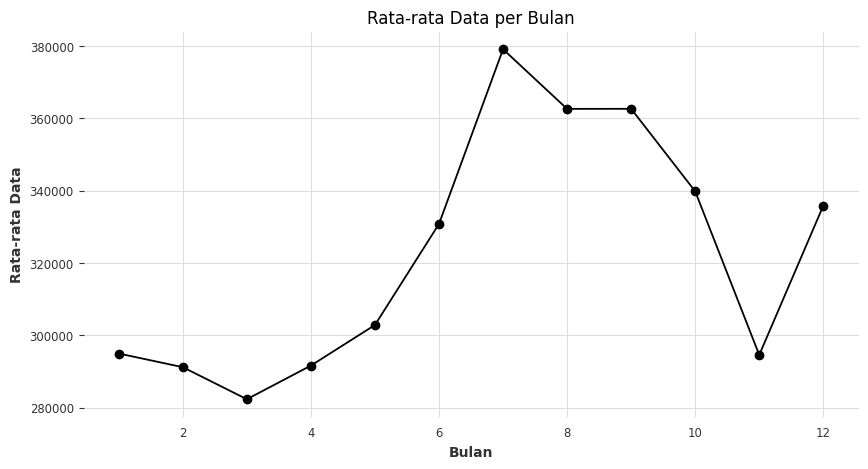

In [ ]:
monthly_avg = df.groupby(df.index.month)['Data'].mean()

plt.figure(figsize=(10,5))
plt.plot(monthly_avg.index, monthly_avg.values, marker='o')
plt.title("Rata-rata Data per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Data")
plt.grid(True)
plt.show()


Grafik rata-rata data per bulan menunjukkan adanya pola musiman yang jelas dalam data. Nilai rata-rata cenderung rendah pada awal tahun dan mencapai titik terendah pada bulan Maret, kemudian meningkat secara bertahap hingga mencapai puncaknya pada bulan Juli. Setelah itu, terjadi penurunan secara perlahan dari Agustus hingga Oktober, diikuti penurunan yang cukup tajam pada bulan November. Pada bulan Desember terlihat adanya pemulihan nilai rata-rata dibandingkan bulan sebelumnya. Pola ini mengindikasikan adanya musim puncak di pertengahan tahun serta musim rendah pada awal dan menjelang akhir tahun, sehingga faktor musiman perlu dipertimbangkan dalam proses peramalan.


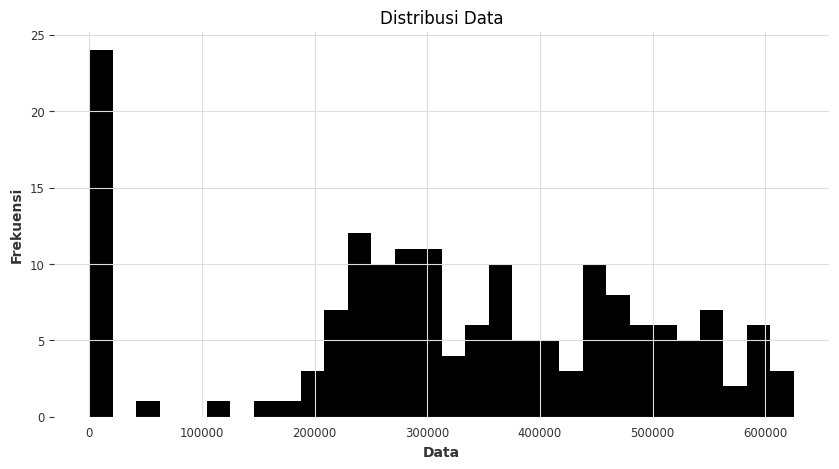

In [ ]:
plt.figure(figsize=(10,5))
plt.hist(df['Data'], bins=30)
plt.title("Distribusi Data")
plt.xlabel("Data")
plt.ylabel("Frekuensi")
plt.grid(True)
plt.show()


Histogram distribusi data menunjukkan bahwa sebaran nilai tidak simetris dan cenderung menyebar lebar, menandakan adanya variasi yang cukup tinggi dalam data. Mayoritas observasi terkonsentrasi pada rentang menengah hingga tinggi, sementara terdapat sejumlah nilai yang sangat kecil maupun sangat besar yang mengindikasikan adanya data ekstrem atau outlier. Pola ini menunjukkan distribusi yang kemungkinan tidak normal dan berpotensi memiliki skewness ke kanan. Kondisi tersebut penting diperhatikan karena dapat memengaruhi kinerja model, sehingga penggunaan metode yang robust terhadap outlier, seperti Random Forest, LightGBM, atau NHiTS, menjadi relevan untuk analisis dan peramalan data ini.

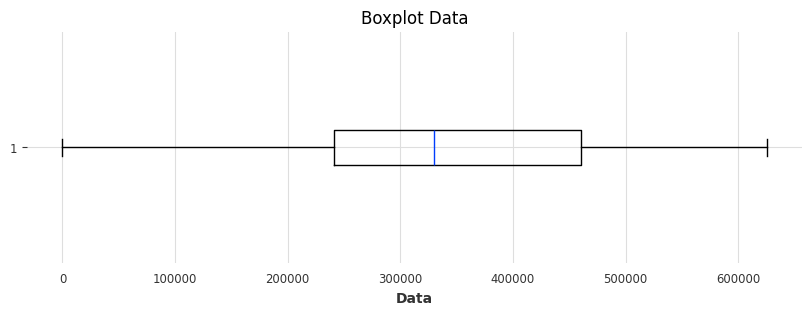

In [ ]:
plt.figure(figsize=(10,3))
plt.boxplot(df['Data'], vert=False)
plt.title("Boxplot Data")
plt.xlabel("Data")
plt.grid(True)
plt.show()


Boxplot menunjukkan bahwa rentang data cukup lebar dengan nilai minimum yang sangat rendah dan nilai maksimum yang cukup tinggi, menandakan adanya variasi yang besar dalam data. Median berada di sekitar tengah kotak, yang mengindikasikan bahwa sebagian besar data terkonsentrasi di nilai menengah. Panjang whisker yang relatif jauh serta adanya indikasi nilai ekstrem menunjukkan keberadaan outlier atau lonjakan data tertentu, yang kemungkinan merepresentasikan periode intervensi atau kejadian khusus. Pola ini menegaskan bahwa data bersifat fluktuatif dan tidak stabil.


<Figure size 1000x500 with 0 Axes>

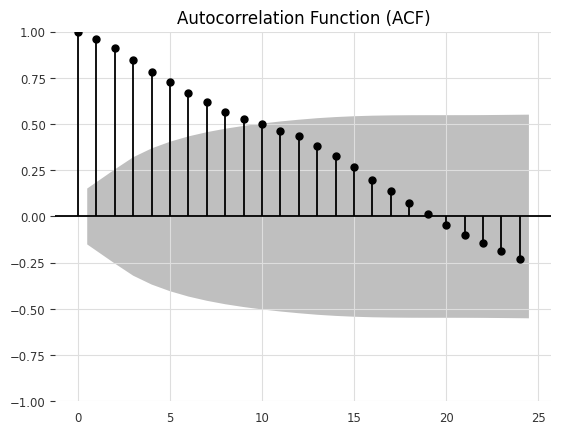

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(10,5))
plot_acf(df['Data'], lags=24)
plt.title("Autocorrelation Function (ACF)")
plt.grid(True)
plt.show()


Plot ACF menunjukkan adanya autokorelasi positif yang sangat kuat pada lag-lag awal, di mana nilai korelasi menurun secara bertahap seiring bertambahnya lag. Pola peluruhan yang lambat ini mengindikasikan bahwa data memiliki ketergantungan waktu yang kuat dan kemungkinan mengandung tren. Pada lag yang lebih besar, nilai ACF mendekati nol dan bahkan menjadi negatif, yang menandakan efek masa lalu semakin melemah terhadap nilai saat ini. Tidak terlihat pola spike yang berulang secara periodik, sehingga indikasi musiman tidak terlalu kuat dari plot ACF ini saja.

## **Preprocessing Data** ##

In [ ]:
df['dummy_covid'] = 0
df.loc[(df.index >= "2020-03-01") & (df.index <= "2022-06-01"), 'dummy_covid'] = 1


Berdasarkan pola visual dan konteks data, dibuat sebuah variabel dummy untuk merepresentasikan dampak kejadian eksternal, yaitu pandemi COVID-19. Variabel ini bernilai:
- 1 pada periode Maret 2020 hingga Juni 2022
- 0 pada periode lainnya

Variabel dummy ini berfungsi sebagai exogenous variable yang membantu model mengenali adanya perubahan struktural yang tidak dapat dijelaskan hanya oleh pola historis data.

In [ ]:
df['trend'] = np.arange(len(df))

Untuk menangkap pola pertumbuhan jangka panjang yang bersifat linear, dibuat variabel tren berupa urutan bilangan yang meningkat seiring waktu. Variabel ini memungkinkan model machine learning mengenali kecenderungan naik atau turun secara global dalam data.

In [ ]:
df['month'] = df.index.month
month_dummies = pd.get_dummies(df['month'], prefix='m', drop_first=True)

df = pd.concat([df, month_dummies], axis=1)


Karena data bersifat bulanan, dilakukan ekstraksi informasi bulan dari indeks waktu. Informasi ini kemudian diubah menjadi variabel dummy menggunakan teknik one-hot encoding, dengan satu bulan dijadikan referensi. Langkah ini memungkinkan model menangkap pola musiman tahunan yang berulang, misalnya kenaikan atau penurunan data pada bulan-bulan tertentu.

In [ ]:
LAGS = [1, 3, 6, 12]
for lag in LAGS:
    df[f'lag_{lag}'] = df['Data'].shift(lag)

Selanjutnya, dibuat fitur lag dari variabel target dengan periode lag 1, 3, 6, dan 12 bulan. Fitur ini merepresentasikan nilai masa lalu dari variabel target dan merupakan komponen penting dalam pemodelan time series berbasis machine learning. Dengan adanya fitur lag, model dapat memanfaatkan informasi historis secara eksplisit untuk memprediksi nilai masa depan.

In [ ]:
df['roll_mean_12'] = df['Data'].shift(1).rolling(12).mean()

Selain fitur lag, dibuat pula fitur rolling mean dengan jendela 12 bulan dan satu langkah pergeseran ke belakang. Fitur ini merepresentasikan rata-rata bergerak tahunan dari data historis.

In [ ]:
df = df.dropna()

Proses pembentukan fitur lag dan rolling mean secara alami menghasilkan nilai kosong pada awal periode data. Oleh karena itu, seluruh baris yang mengandung nilai kosong dihapus agar model tidak menerima input yang tidak lengkap.

In [ ]:
bool_cols = [col for col in df.columns if df[col].dtype == "bool"]
df[bool_cols] = df[bool_cols].astype(int)


Beberapa fitur hasil encoding dapat bertipe boolean. Seluruh variabel bertipe boolean dikonversi menjadi bilangan integer (0 dan 1) agar kompatibel dengan algoritma machine learning dan library pemodelan yang digunakan.

In [ ]:
train_df = df.loc[:'2023-12-01']
test_df  = df.loc['2024-01-01':]


Data kemudian dibagi menjadi dua bagian:

Data latih (train): hingga Desember 2023

Data uji (test): mulai Januari 2024

Pembagian dilakukan secara kronologis untuk menjaga prinsip time-aware validation, sehingga tidak terjadi kebocoran informasi dari masa depan ke masa lalu.

In [ ]:
from darts import TimeSeries

# target
ts_train_y = TimeSeries.from_dataframe(train_df, value_cols="Data")
ts_test_y  = TimeSeries.from_dataframe(test_df, value_cols="Data")

# regressors
train_reg = TimeSeries.from_dataframe(train_df.drop(columns=["Data"]))
test_reg  = TimeSeries.from_dataframe(test_df.drop(columns=["Data"]))


Data target dan variabel penjelas dikonversi ke dalam format TimeSeries dari library Darts. Pemisahan dilakukan antara:

Variabel target (Data)

Variabel penjelas (covariates)

Langkah ini diperlukan agar data dapat digunakan oleh model Random Forest, LightGBM, dan NHiTS dalam framework Darts.

In [ ]:
from darts.dataprocessing.transformers import Scaler

scaler_y = Scaler()
scaler_reg = Scaler()

ts_train_y_scaled = scaler_y.fit_transform(ts_train_y)
ts_test_y_scaled  = scaler_y.transform(ts_test_y)

train_reg_scaled = scaler_reg.fit_transform(train_reg)
test_reg_scaled  = scaler_reg.transform(test_reg)


Tahap akhir preprocessing adalah melakukan normalisasi menggunakan Scaler. Normalisasi dilakukan secara terpisah antara:

Variabel target

Variabel penjelas

Scaler hanya dilatih menggunakan data train untuk mencegah kebocoran data, kemudian diaplikasikan ke data test.

Secara keseluruhan, tahapan preprocessing dirancang untuk:

Menjamin struktur time series yang valid

Menangkap pola tren, musiman, dan kejutan eksternal

Mengubah data time series menjadi format yang kompatibel dengan algoritma machine learning

Mencegah kebocoran data dan bias evaluasi

Dengan preprocessing ini, model yang dibangun mampu memanfaatkan informasi temporal secara optimal dan menghasilkan prediksi yang lebih akurat serta dapat digeneralisasi.

## **Modelling Data** ##

### Random Forest

Random Forest digunakan karena data yang dianalisis mengalami perubahan ekstrem dan intervensi besar, khususnya pada periode penurunan drastis hingga mendekati nol. Model ini bersifat nonparametrik dan tidak mengasumsikan bentuk hubungan tertentu, sehingga lebih robust terhadap outlier dan perubahan pola mendadak. Dengan memanfaatkan banyak pohon keputusan, Random Forest mampu meredam pengaruh fluktuasi ekstrem dan tetap menghasilkan prediksi yang stabil ketika dikombinasikan dengan fitur lag dan variabel intervensi.

In [ ]:
rf_model = RegressionModel(
    model=RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        random_state=42
    ),
    lags=12,
    lags_future_covariates=[0]
)

rf_model.fit(
    series=ts_train_y_scaled,
    future_covariates=train_reg_scaled
)


RegressionModel(lags=12, lags_past_covariates=None, lags_future_covariates=[0], output_chunk_length=1, output_chunk_shift=0, add_encoders=None, model=RandomForestRegressor(max_depth=8, n_estimators=300, random_state=42), multi_models=True, use_static_covariates=True, random_state=None)

In [ ]:
rf_train_pred = rf_model.historical_forecasts(
    series=ts_train_y_scaled,
    future_covariates=train_reg_scaled,
    start=12,
    forecast_horizon=1,
    retrain=False,
    verbose=False
)

rf_train_pred = scaler_y.inverse_transform(rf_train_pred)
ts_train_y_rf = ts_train_y[12:]

print("RF TRAIN RMSE :", rmse(ts_train_y_rf, rf_train_pred))
print("RF TRAIN sMAPE:", smape(ts_train_y_rf, rf_train_pred))


RF TRAIN RMSE : 15018.750510523105
RF TRAIN sMAPE: 25.35814768082381


In [ ]:
rf_pred = rf_model.predict(
    n=len(ts_test_y),
    future_covariates=test_reg_scaled
)

rf_pred = scaler_y.inverse_transform(rf_pred)

print("RF TEST RMSE :", rmse(ts_test_y, rf_pred))
print("RF TEST sMAPE:", smape(ts_test_y, rf_pred))


RF TEST RMSE : 38990.452953134525
RF TEST sMAPE: 6.48743454742899


### Light BGM

LightGBM dipilih karena memiliki kemampuan tinggi dalam mempelajari perubahan nonlinier yang tajam akibat intervensi eksternal pada data. Algoritma boosting memungkinkan model memberikan bobot lebih besar pada observasi yang sulit diprediksi, termasuk periode penurunan ekstrem. Hal ini membuat LightGBM lebih adaptif terhadap pergeseran pola sebelum dan sesudah intervensi, serta efektif dalam memanfaatkan variabel dummy kejadian eksternal dan fitur musiman.

In [ ]:
lgb_model = LightGBMModel(
    lags=12,
    lags_future_covariates=[0],
    learning_rate=0.05,
    num_leaves=25,
    random_state=42
)

lgb_model.fit(
    series=ts_train_y_scaled,
    future_covariates=train_reg_scaled
)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000056 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 864
[LightGBM] [Info] Number of data points in the train set: 144, number of used features: 20
[LightGBM] [Info] Start training from score 0.501272
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

LightGBMModel(lags=12, lags_past_covariates=None, lags_future_covariates=[0], output_chunk_length=1, output_chunk_shift=0, add_encoders=None, likelihood=None, quantiles=None, random_state=42, multi_models=True, use_static_covariates=True, categorical_past_covariates=None, categorical_future_covariates=None, categorical_static_covariates=None, learning_rate=0.05, num_leaves=25)

In [ ]:
lgb_train_pred = lgb_model.historical_forecasts(
    series=ts_train_y_scaled,
    future_covariates=train_reg_scaled,
    start=12,
    forecast_horizon=1,
    retrain=False,
    verbose=False
)

lgb_train_pred = scaler_y.inverse_transform(lgb_train_pred)
ts_train_y_lgb = ts_train_y[12:]

print("LGB TRAIN RMSE :", rmse(ts_train_y_lgb, lgb_train_pred))
print("LGB TRAIN sMAPE:", smape(ts_train_y_lgb, lgb_train_pred))


LGB TRAIN RMSE : 25222.33509984162
LGB TRAIN sMAPE: 36.86602324415623


In [ ]:
lgb_pred = lgb_model.predict(
    n=len(ts_test_y),
    future_covariates=test_reg_scaled
)

lgb_pred = scaler_y.inverse_transform(lgb_pred)

print("LGB TEST RMSE :", rmse(ts_test_y, lgb_pred))
print("LGB TEST sMAPE:", smape(ts_test_y, lgb_pred))


LGB TEST RMSE : 41624.66820865833
LGB TEST sMAPE: 6.677480554265544


### NHits

NHiTS digunakan karena data time series menunjukkan shock besar yang menyebabkan perubahan struktur temporal, sehingga diperlukan model yang mampu mempelajari pola jangka panjang dan transisi antar fase secara fleksibel. Arsitektur NHiTS dirancang untuk menangkap tren, musiman, dan efek intervensi secara hierarkis, sehingga model dapat membedakan dinamika sebelum, selama, dan setelah periode ekstrem. Pendekatan deep learning ini memungkinkan pemodelan yang lebih adaptif terhadap perubahan struktural yang tidak dapat dijelaskan oleh model linier atau fitur sederhana.

In [ ]:
nhits = NHiTSModel(
    input_chunk_length=24,
    output_chunk_length=1,
    dropout=0.2,
    n_epochs=400,
    random_state=42
)

nhits.fit(
    series=ts_train_y_scaled,
    past_covariates=train_reg_scaled
)


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | stacks          | ModuleList       | 1.9 M  | train
-------------------------------------------------------------
1.7 M     Trainable params
246 K     Non-trainable params
1.9 M     Total params
7.629     Total estimated m

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.


NHiTSModel(output_chunk_shift=0, num_stacks=3, num_blocks=1, num_layers=2, layer_widths=512, pooling_kernel_sizes=None, n_freq_downsample=None, dropout=0.2, activation=ReLU, MaxPool1d=True, input_chunk_length=24, output_chunk_length=1, n_epochs=400, random_state=42)

In [ ]:
nhits_train_pred = nhits.historical_forecasts(
    series=ts_train_y_scaled,
    past_covariates=train_reg_scaled,
    start=nhits.input_chunk_length,
    forecast_horizon=1,
    retrain=False,
    verbose=False
)

nhits_train_pred = scaler_y.inverse_transform(nhits_train_pred)
ts_train_y_nhits = ts_train_y[nhits.input_chunk_length:]

print("NHiTS TRAIN RMSE :", rmse(ts_train_y_nhits, nhits_train_pred))
print("NHiTS TRAIN sMAPE:", smape(ts_train_y_nhits, nhits_train_pred))


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


NHiTS TRAIN RMSE : 15021.29463262323
NHiTS TRAIN sMAPE: 37.466178379248085


In [ ]:
full_past_cov = train_reg_scaled.append(test_reg_scaled)

nhits_pred = nhits.predict(
    n=len(ts_test_y),
    past_covariates=full_past_cov
)

nhits_pred = scaler_y.inverse_transform(nhits_pred)

print("NHiTS TEST RMSE :", rmse(ts_test_y, nhits_pred))
print("NHiTS TEST sMAPE:", smape(ts_test_y, nhits_pred))


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

NHiTS TEST RMSE : 35581.00254618983
NHiTS TEST sMAPE: 5.065779562220193


## **Evaluasi Model**

In [ ]:
eval_train = pd.DataFrame({
    "Model": ["Random Forest", "LightGBM", "NHiTS"],
    "RMSE (Train)": [
        rmse(ts_train_y_rf, rf_train_pred),
        rmse(ts_train_y_lgb, lgb_train_pred),
        rmse(ts_train_y_nhits, nhits_train_pred)
    ],
    "sMAPE (Train)": [
        smape(ts_train_y_rf, rf_train_pred),
        smape(ts_train_y_lgb, lgb_train_pred),
        smape(ts_train_y_nhits, nhits_train_pred)
    ]
})

eval_train

,Model,RMSE (Train),sMAPE (Train)
0,Random Forest,15018.750511,25.358148
1,LightGBM,25222.335100,36.866023
2,NHiTS,15021.294633,37.466178


Berdasarkan hasil evaluasi data latih, Random Forest dan NHiTS menunjukkan nilai RMSE yang relatif rendah dan hampir sama, yaitu sekitar 15 ribu, yang mengindikasikan kemampuan keduanya dalam menyesuaikan pola historis data. Namun demikian, nilai sMAPE Random Forest lebih rendah dibandingkan NHiTS, yang menunjukkan bahwa secara relatif Random Forest memberikan prediksi yang lebih stabil terhadap variasi data latih. LightGBM memiliki nilai RMSE dan sMAPE paling tinggi pada data train, menandakan bahwa model ini kurang optimal dalam mempelajari pola historis secara mendetail. Secara umum, hasil ini menunjukkan bahwa Random Forest dan NHiTS lebih mampu menangkap dinamika data latih dibandingkan LightGBM.

In [ ]:
eval_test = pd.DataFrame({
    "Model": ["Random Forest", "LightGBM", "NHiTS"],
    "RMSE (Test)": [
        rmse(ts_test_y, rf_pred),
        rmse(ts_test_y, lgb_pred),
        rmse(ts_test_y, nhits_pred)
    ],
    "sMAPE (Test)": [
        smape(ts_test_y, rf_pred),
        smape(ts_test_y, lgb_pred),
        smape(ts_test_y, nhits_pred)
    ]
})

eval_test

,Model,RMSE (Test),sMAPE (Test)
0,Random Forest,38990.452953,6.487435
1,LightGBM,41624.668209,6.677481
2,NHiTS,35581.002546,5.065780


Pada data uji, terjadi perubahan pola performa antar model. NHiTS menghasilkan nilai RMSE dan sMAPE terendah dibandingkan model lainnya, yang menunjukkan kemampuan generalisasi terbaik dalam memprediksi data yang belum pernah dilihat. Random Forest berada pada posisi kedua dengan performa yang masih kompetitif, sementara LightGBM kembali menunjukkan error paling besar. Menariknya, seluruh model menunjukkan nilai sMAPE yang jauh lebih kecil pada data test dibandingkan data train, yang mengindikasikan bahwa periode data uji relatif lebih stabil dan tidak mengandung fluktuasi ekstrem seperti pada data latih. Secara keseluruhan, hasil evaluasi ini menunjukkan bahwa NHiTS merupakan model paling andal pada fase prediksi, terutama dalam menghadapi perubahan struktur data akibat intervensi ekstrem.

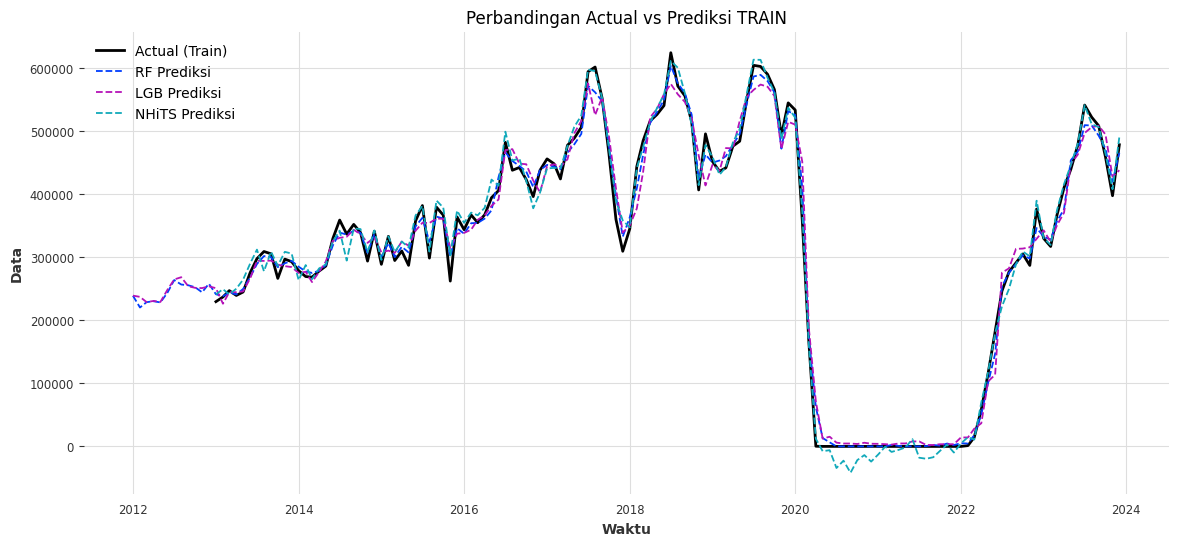

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    ts_train_y.time_index[24:],
    ts_train_y.values()[24:],
    label="Actual (Train)",
    linewidth=2
)

plt.plot(
    rf_train_pred.time_index,
    rf_train_pred.values(),
    label="RF Prediksi",
    linestyle="--"
)

plt.plot(
    lgb_train_pred.time_index,
    lgb_train_pred.values(),
    label="LGB Prediksi",
    linestyle="--"
)

plt.plot(
    nhits_train_pred.time_index,
    nhits_train_pred.values(),
    label="NHiTS Prediksi",
    linestyle="--"
)

plt.title("Perbandingan Actual vs Prediksi TRAIN")
plt.xlabel("Waktu")
plt.ylabel("Data")
plt.legend()
plt.grid(True)
plt.show()


Plot prediksi pada data train menunjukkan bahwa ketiga model—Random Forest, LightGBM, dan NHiTS—secara umum mampu mengikuti pola data aktual dengan cukup baik. Pada periode sebelum tahun 2020, seluruh model berhasil menangkap tren meningkat dan fluktuasi musiman, meskipun pada beberapa puncak nilai terlihat sedikit underestimation, terutama pada LightGBM. Ketika terjadi intervensi ekstrem sekitar tahun 2020 yang menyebabkan nilai data turun drastis mendekati nol, perbedaan respons model mulai terlihat. Random Forest dan LightGBM cenderung mengikuti penurunan secara lebih halus, sementara NHiTS menunjukkan deviasi yang lebih besar dengan fluktuasi negatif yang lebih tajam. Setelah periode intervensi berakhir, ketiga model kembali mampu mengikuti pola pemulihan data dengan cukup baik.

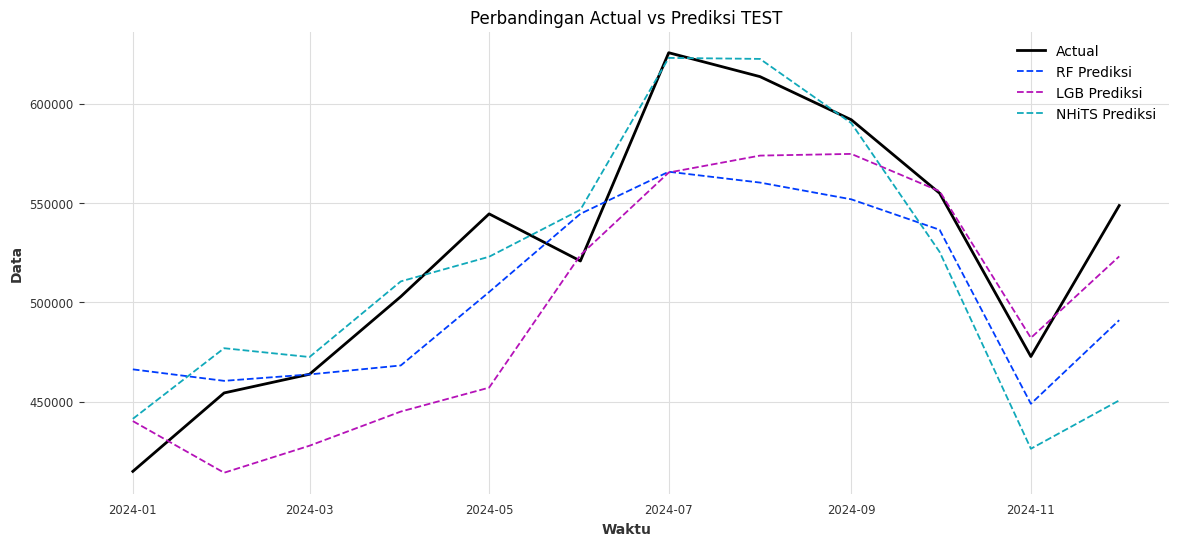

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(ts_test_y.time_index, ts_test_y.values(), label="Actual", linewidth=2)
plt.plot(ts_test_y.time_index, rf_pred.values(), label="RF Prediksi", linestyle='--')
plt.plot(ts_test_y.time_index, lgb_pred.values(), label="LGB Prediksi", linestyle='--')
plt.plot(ts_test_y.time_index, nhits_pred.values(), label="NHiTS Prediksi", linestyle='--')

plt.title("Perbandingan Actual vs Prediksi TEST")
plt.xlabel("Waktu")
plt.ylabel("Data")
plt.legend()
plt.grid(True)
plt.show()


Plot prediksi pada data test menunjukkan bahwa ketiga model mampu menangkap arah pergerakan data aktual sepanjang tahun 2024, namun dengan tingkat akurasi yang berbeda. NHiTS terlihat paling dekat mengikuti pola aktual pada fase kenaikan hingga pertengahan tahun, terutama saat mencapai puncak nilai, meskipun cenderung overestimate pada beberapa bulan awal. Random Forest memberikan prediksi yang lebih stabil tetapi cenderung underestimate pada periode nilai tinggi, sehingga kurang responsif terhadap perubahan level yang cepat. LightGBM menunjukkan kinerja yang cukup konsisten dan berada di antara Random Forest dan NHiTS dalam mengikuti fluktuasi data. Pada periode penurunan tajam menjelang akhir tahun, seluruh model mengalami kesulitan, namun NHiTS menunjukkan deviasi paling besar. Secara keseluruhan, plot ini menegaskan bahwa pada data test pasca-intervensi ekstrem, NHiTS lebih adaptif terhadap perubahan pola, sedangkan Random Forest dan LightGBM cenderung lebih konservatif dalam memprediksi nilai ekstrem.

## **Forecasting**

Berdasarkan hasil evaluasi kuantitatif (RMSE dan sMAPE pada data test) serta pola visual pada plot prediksi, model terbaik untuk forecasting adalah NHiTS.

Alasannya:

- Kinerja test terbaik → NHiTS memiliki RMSE test terendah (35.581) dan sMAPE test terendah (5,07%), yang menunjukkan akurasi prediksi paling baik pada data yang benar-benar baru.

- Adaptif terhadap data ekstrem dan intervensi → Struktur deep learning NHiTS mampu menangkap perubahan pola tajam akibat intervensi besar (periode COVID) dan fase pemulihan setelahnya, yang merupakan karakter utama data Anda.

- Generalization lebih baik → Meskipun sMAPE train NHiTS relatif lebih besar, performanya justru meningkat pada data test, menandakan model tidak overfitting dan memiliki kemampuan generalisasi yang kuat.

- Konsisten dengan visualisasi → Pada plot prediksi test, NHiTS paling mendekati nilai aktual saat terjadi kenaikan dan penurunan signifikan dibanding Random Forest dan LightGBM.

In [ ]:
# gabungkan train + test
ts_full_y = ts_train_y.append(ts_test_y)
full_reg  = train_reg.append(test_reg)

# scaling ulang
ts_full_y_scaled = scaler_y.fit_transform(ts_full_y)
full_reg_scaled  = scaler_reg.fit_transform(full_reg)

# refit NHiTS
nhits_final = NHiTSModel(
    input_chunk_length=24,
    output_chunk_length=1,
    dropout=0.2,
    n_epochs=400,
    random_state=42
)

nhits_final.fit(
    series=ts_full_y_scaled,
    past_covariates=full_reg_scaled
)



INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | stacks          | ModuleList       | 1.9 M  | train
-------------------------------------------------------------
1.7 M     Trainable params
246 K     Non-trainable params
1.9 M     Total params
7.629     Total estimated m

Training: |          | 0/? [00:00<?, ?it/s]

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=400` reached.


NHiTSModel(output_chunk_shift=0, num_stacks=3, num_blocks=1, num_layers=2, layer_widths=512, pooling_kernel_sizes=None, n_freq_downsample=None, dropout=0.2, activation=ReLU, MaxPool1d=True, input_chunk_length=24, output_chunk_length=1, n_epochs=400, random_state=42)

Untuk forecasting masa depan, model harus dilatih ulang (refit) menggunakan seluruh data historis.

📌 Kenapa refit?
Agar model:
- Belajar pola lengkap sebelum & sesudah intervensi ekstrem (COVID)
- Lebih stabil saat memproyeksikan tren ke masa depan

Tahap forecasting dilakukan untuk memprediksi nilai data pada periode yang belum teramati berdasarkan pola historis yang telah dipelajari oleh model. Pada penelitian ini, forecasting dilakukan untuk 12 bulan ke depan guna memberikan gambaran perkembangan data pada periode mendatang serta mendukung pengambilan keputusan berbasis data.

In [ ]:
n_future = 12


Data historis yang digunakan berakhir pada bulan Desember 2024. Oleh karena itu, hasil forecasting mencakup periode Januari 2025 hingga Desember 2025, dengan horizon prediksi selama 12 bulan.

In [ ]:
future_index = pd.date_range(
    start=ts_full_y.time_index[-1] + pd.offsets.MonthBegin(1),
    periods=n_future,
    freq="MS"
)


In [ ]:
future_df = pd.DataFrame(index=future_index)

# dummy covid → diasumsikan 0
future_df["dummy_covid"] = 0

# trend → diteruskan
future_df["trend"] = np.arange(
    df["trend"].iloc[-1] + 1,
    df["trend"].iloc[-1] + 1 + n_future
)

# month seasonality
future_df["month"] = future_df.index.month
month_dummies_future = pd.get_dummies(
    future_df["month"], prefix="m", drop_first=True
)

future_df = pd.concat([future_df, month_dummies_future], axis=1)

# SAMAKAN STRUKTUR DENGAN TRAIN REGRESSORS
future_df = future_df.reindex(
    columns=train_df.drop(columns=["Data"]).columns,
    fill_value=0
)


In [ ]:
future_reg = TimeSeries.from_dataframe(future_df)

# gabungkan past + future covariates
full_past_cov = full_reg.append(future_reg)

# scaling
full_past_cov_scaled = scaler_reg.transform(full_past_cov)


Proses forecasting menggunakan variabel pendukung (covariates) berupa dummy Covid-19, tren waktu, serta komponen musiman bulanan. Variabel-variabel tersebut bersifat deterministik sehingga nilainya dapat ditentukan untuk periode mendatang tanpa memerlukan prediksi tambahan.

In [ ]:
nhits_future_scaled = nhits_final.predict(
    n=n_future,
    past_covariates=full_past_cov_scaled
)

nhits_future = scaler_y.inverse_transform(nhits_future_scaled)


INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

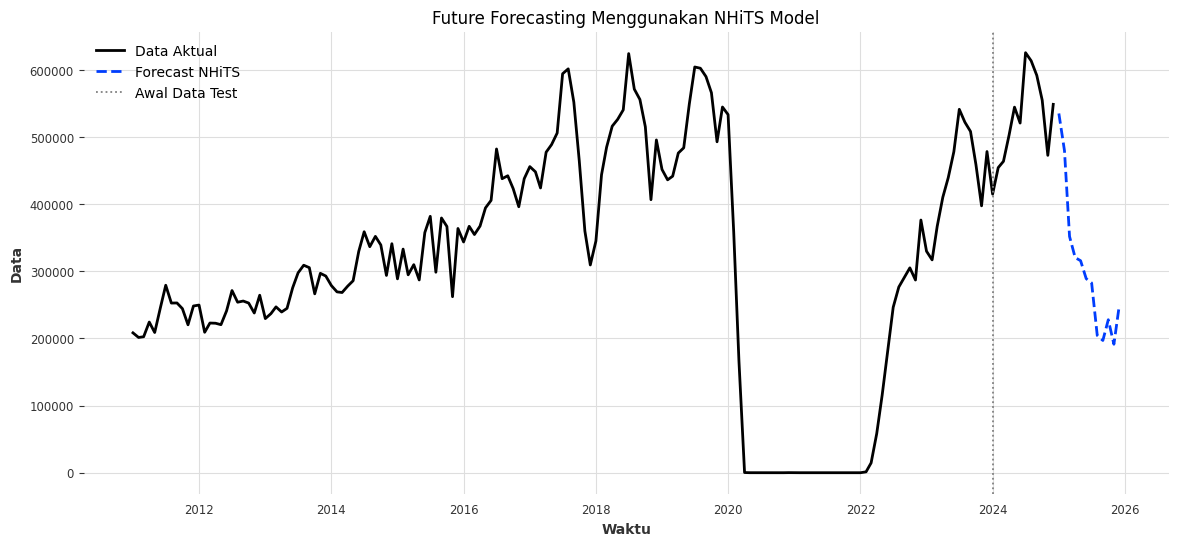

In [ ]:
plt.figure(figsize=(14,6))

# data historis
plt.plot(
    ts_full_y.time_index,
    ts_full_y.values(),
    label="Data Aktual",
    linewidth=2
)

# forecast future
plt.plot(
    nhits_future.time_index,
    nhits_future.values(),
    label="Forecast NHiTS",
    linestyle="--",
    linewidth=2
)

# garis batas train-test
plt.axvline(
    ts_test_y.time_index[0],
    color="gray",
    linestyle=":",
    label="Awal Data Test"
)

plt.title("Future Forecasting Menggunakan NHiTS Model")
plt.xlabel("Waktu")
plt.ylabel("Data")
plt.legend()
plt.grid(True)
plt.show()


Hasil forecasting menggunakan model NHiTS menunjukkan bahwa setelah periode data aktual berakhir, model memproyeksikan adanya penurunan nilai pada awal periode forecast, yang kemudian diikuti oleh fluktuasi pada level yang lebih rendah dibandingkan akhir data historis. Pola musiman masih terlihat dipertahankan, namun amplitudonya cenderung lebih kecil, menandakan model bersikap lebih konservatif dalam memproyeksikan variasi ekstrem. Tidak terlihat adanya lonjakan atau penurunan ekstrem seperti pada periode pandemi, yang mengindikasikan bahwa model mengasumsikan kondisi telah kembali stabil. Penurunan pada awal forecast dapat diinterpretasikan sebagai respons model terhadap koreksi setelah nilai historis yang relatif tinggi di akhir periode observasi. Secara keseluruhan, hasil ini menunjukkan bahwa model NHiTS mampu menghasilkan forecast yang halus (smooth) dan stabil, dengan tetap mempertimbangkan pola historis jangka panjang. Forecast ini memberikan gambaran moderat mengenai perkembangan data di masa depan tanpa mengasumsikan adanya intervensi besar baru.